In [7]:
import pandas as pd

# load the csv
clean_telco_df = pd.read_csv("../data/clean_telco_df.csv")

In [8]:
# identify churn
clean_telco_df["Churn"].value_counts(normalize=True)

Churn
0    0.734215
1    0.265785
Name: proportion, dtype: float64

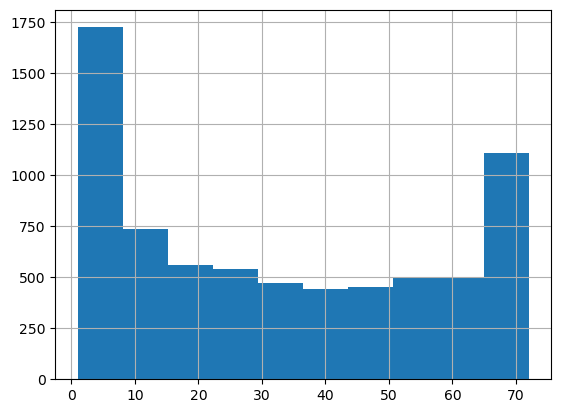

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# visualize tenure distribution
clean_telco_df["tenure"].hist()
plt.show()

<Axes: xlabel='Churn', ylabel='tenure'>

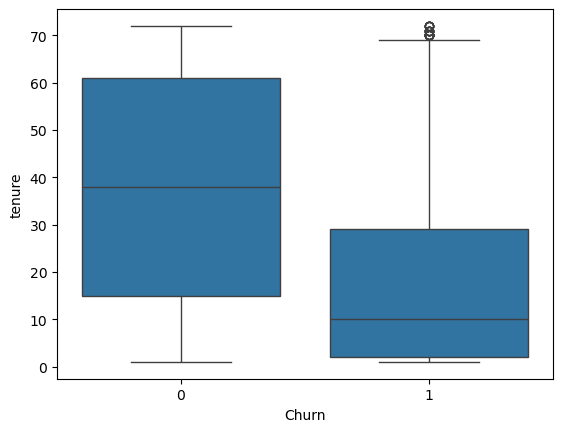

In [10]:
import seaborn as sns

# tenure box plot
sns.boxplot(x="Churn", y="tenure", data=clean_telco_df)

Contract_One year
0    0.306295
1    0.112772
Name: Churn, dtype: float64
Contract_Two year
0    0.340565
1    0.028487
Name: Churn, dtype: float64


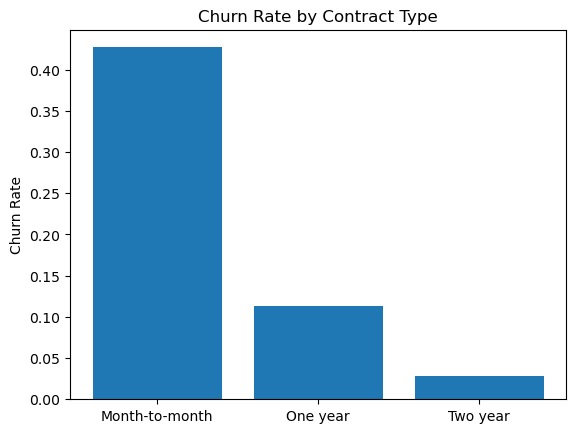

In [ ]:
# contract churn rate

print(clean_telco_df.groupby("Contract_One year")["Churn"].mean())

# one year has ~11% churn
print(clean_telco_df.groupby("Contract_Two year")["Churn"].mean())

contract_churn = {
    "Month-to-month": clean_telco_df[(clean_telco_df["Contract_One year"]==0) & (clean_telco_df["Contract_Two year"]==0)]["Churn"].mean(),
    "One year": clean_telco_df[clean_telco_df["Contract_One year"]==1]["Churn"].mean(),
    "Two year": clean_telco_df[clean_telco_df["Contract_Two year"]==1]["Churn"].mean()
}

plt.bar(contract_churn.keys(), contract_churn.values())
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate")
plt.show()

In [14]:
# internet churn rate

clean_telco_df.groupby("InternetService_Fiber optic")["Churn"].mean()

# fiber users have ~41.9% churn
# non-fiber users have ~14.5% churn

InternetService_Fiber optic
0    0.145325
1    0.418928
Name: Churn, dtype: float64

In [ ]:
# payment method churn rate

clean_telco_df.groupby("PaymentMethod_Electronic check")["Churn"].mean()

PaymentMethod_Electronic check
0    0.170988
1    0.452854
Name: Churn, dtype: float64

In [16]:
# senior citizen churn rate

clean_telco_df.groupby("SeniorCitizen")["Churn"].mean()

SeniorCitizen
0    0.236503
1    0.416813
Name: Churn, dtype: float64

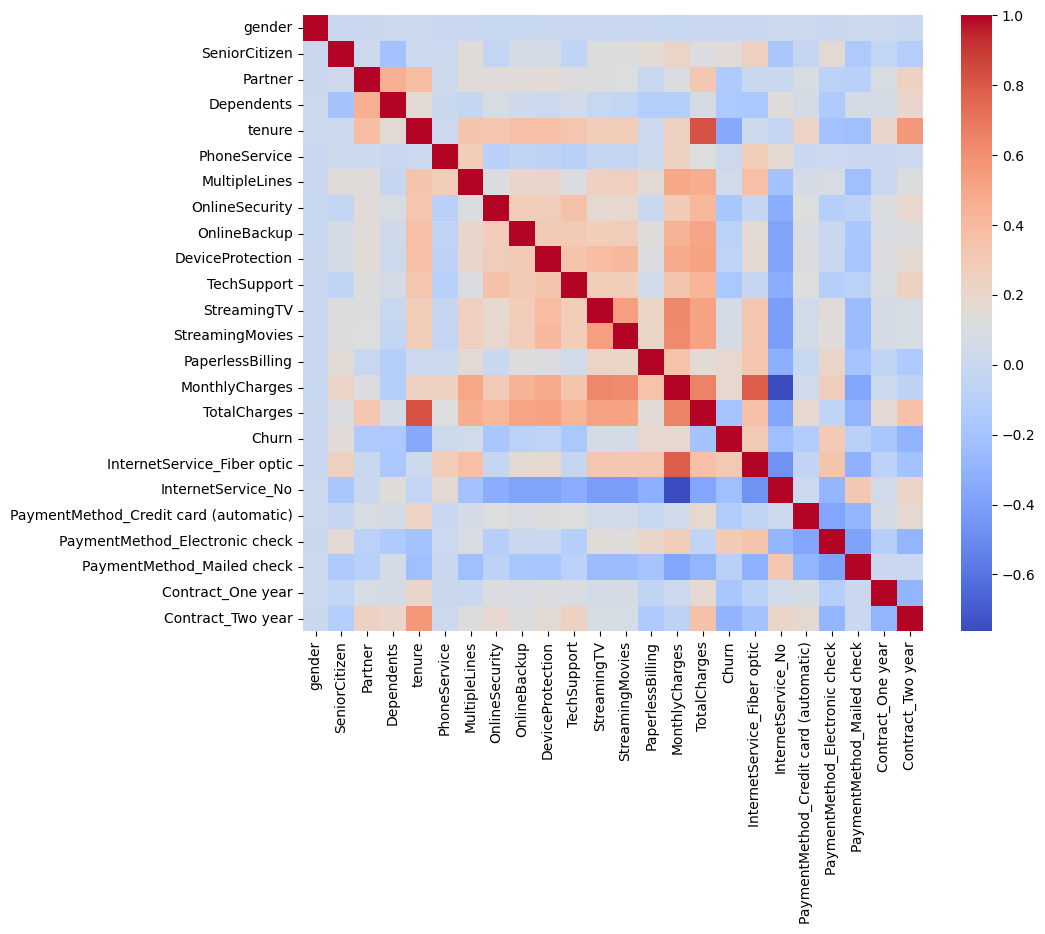

tenure                                  -0.354049
Contract_Two year                       -0.301552
InternetService_No                      -0.227578
TotalCharges                            -0.199484
Contract_One year                       -0.178225
OnlineSecurity                          -0.171270
TechSupport                             -0.164716
Dependents                              -0.163128
Partner                                 -0.149982
PaymentMethod_Credit card (automatic)   -0.134687
PaymentMethod_Mailed check              -0.090773
OnlineBackup                            -0.082307
DeviceProtection                        -0.066193
gender                                  -0.008545
PhoneService                             0.011691
MultipleLines                            0.040033
StreamingMovies                          0.060860
StreamingTV                              0.063254
SeniorCitizen                            0.150541
PaperlessBilling                         0.191454


In [20]:
# dataset correlation heatmap

numeric_df = clean_telco_df.select_dtypes(include=["number"])

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), cmap="coolwarm")

plt.show()
print(clean_telco_df.corr()["Churn"].sort_values())

In [21]:
print(clean_telco_df.groupby(["Contract_One year", "Churn"])["tenure"].mean())
print(clean_telco_df.groupby(["InternetService_Fiber optic", "PaymentMethod_Electronic check"])["Churn"].mean())

Contract_One year  Churn
0                  0        36.276640
                   1        15.348796
1                  0        41.705972
                   1        44.963855
Name: tenure, dtype: float64
InternetService_Fiber optic  PaymentMethod_Electronic check
0                            0                                 0.110550
                             1                                 0.288312
1                            0                                 0.298468
                             1                                 0.532288
Name: Churn, dtype: float64


In [22]:
# feature engineering

clean_telco_df["HighRisk"] = (
    (clean_telco_df["tenure"] < 12) &
    (clean_telco_df["Contract_One year"] == 0) &
    (clean_telco_df["Contract_Two year"] == 0)
)
clean_telco_df.groupby("HighRisk")["Churn"].mean()

HighRisk
False    0.171351
True     0.519392
Name: Churn, dtype: float64

In [57]:
# export dashboard csv

df_raw = pd.read_csv("../data/telco_customer_churn.csv")
df_raw = df_raw[pd.to_numeric(df_raw["TotalCharges"], errors="coerce").notna()].reset_index(drop=True)

clean_telco_df["Contract"] = df_raw["Contract"].values
clean_telco_df["InternetService"] = df_raw["InternetService"].values
clean_telco_df["PaymentMethod"] = df_raw["PaymentMethod"].values

clean_telco_df["churn_probability"] = model.predict_proba(X)[:, 1]
clean_telco_df.to_csv("../data/churn_dashboard_data.csv", index=False)

clean_telco_df

c:\Users\dillo\anaconda3\envs\ChurnDsProj\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Contract_One year,Contract_Two year,HighRisk,Contract,InternetService,PaymentMethod,churn_probability
0,0,0,1,0,1,0,0,0,1,0,...,0,1,0,0,0,True,Month-to-month,DSL,Electronic check,0.000002
1,1,0,0,0,34,1,0,1,0,1,...,0,0,1,1,0,False,One year,DSL,Mailed check,1.000000
2,1,0,0,0,2,1,0,1,1,0,...,0,0,1,0,0,True,Month-to-month,DSL,Mailed check,0.000835
3,1,0,0,0,45,0,0,1,0,1,...,0,0,0,1,0,False,One year,DSL,Bank transfer (automatic),1.000000
4,0,0,0,0,2,1,0,0,0,0,...,0,1,0,0,0,True,Month-to-month,Fiber optic,Electronic check,0.011864
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,1,0,1,1,24,1,1,1,0,1,...,0,0,1,1,0,False,One year,DSL,Mailed check,1.000000
7028,0,0,1,1,72,1,1,0,1,1,...,1,0,0,1,0,False,One year,Fiber optic,Credit card (automatic),1.000000
7029,0,0,1,1,11,0,0,1,0,0,...,0,1,0,0,0,True,Month-to-month,DSL,Electronic check,1.000000
7030,1,1,1,0,4,1,1,0,0,0,...,0,0,1,0,0,True,Month-to-month,Fiber optic,Mailed check,1.000000
